# MCP 기초 — 서버를 띄우고 에이전트에 붙이기

**MCP(Model Context Protocol)** 는 LLM 애플리케이션이 외부 도구·데이터에 접근하는 **표준 규격**입니다.
도구를 직접 만드는 대신 **이미 만들어진 서버를 꽂아 쓰는** 방식입니다.

## 이 노트북의 흐름

| 부 | 내용 |
|---|---|
| **1부** | `uvx` · `npx` 로 MCP 서버 띄우기 → 에이전트에 연결 → 원격 MCP 서버 |
| **2부** | 같은 서버를 **Docker** 로 띄우기 (격리) |

## 서버를 띄우는 세 가지 방법

| 방법 | 전송 | 서버가 도는 곳 | 이 노트북에서 |
|---|---|---|---|
| `MCPServerStdio` + `uvx`/`npx` | 표준입출력 | 내 PC (자식 프로세스) | fetch · playwright · filesystem |
| `MCPServerStdio` + `docker run` | 표준입출력 | 내 PC (컨테이너) | 2부 |
| `MCPServerStreamableHttp` | HTTP | **다른 호스트** | Context7 |

> **준비물**: `uvx`(Python), `npx`(Node.js). 2부는 Docker Desktop이 추가로 필요합니다.

---

## Step 0. 준비

`agents` 는 OpenAI Agents SDK 입니다. `MCPServerStdio` 가 MCP 서버를 자식 프로세스로 띄워 줍니다.

In [1]:
from dotenv import load_dotenv
from agents import Agent, Runner, trace
from agents.mcp import MCPServerStdio
from IPython.display import Image, display
import os

load_dotenv(override=True)

True

## Step 1. 주피터에서 꼭 필요한 손질

MCP의 stdio 서버는 **자식 프로세스**로 뜹니다. 그런데 노트북에서 그냥 연결하면 이렇게 실패합니다.

```
io.UnsupportedOperation: fileno
```

MCP 라이브러리는 서버의 오류 출력을 `sys.stderr` 로 보내는데,
**주피터의 `sys.stderr` 는 진짜 파일이 아니라** 결과창으로 보내는 가짜 객체입니다.
파일 번호(`fileno`)가 없어서 하위 프로세스에 넘길 수 없습니다.

그래서 오류 출력을 **진짜 파일**로 돌려 줍니다. 터미널에서 `.py` 로 실행할 때는 필요 없습니다.

> 아래에서 `DEVNULL`(버리기) 대신 **파일**에 남깁니다.
> 서버가 뜨지 않을 때 원인을 볼 수 있어야 하기 때문입니다 — 2부의 "자주 만나는 문제"에서 실제로 필요해집니다.

In [2]:
import functools

import agents.mcp.server

# 주피터의 sys.stderr 에는 파일 번호가 없어 하위 프로세스에 넘길 수 없다.
# 서버의 오류 출력을 진짜 파일로 돌려 둔다. (DEVNULL 로 버리면 원인을 못 본다)
MCP_LOG = open("mcp_basic_server.log", "w", encoding="utf-8")
agents.mcp.server.stdio_client = functools.partial(
    agents.mcp.server.stdio_client, errlog=MCP_LOG)

print("MCP 서버 오류 로그 -> mcp_basic_server.log")

MCP 서버 오류 로그 -> mcp_basic_server.log


## Step 2. 첫 번째 MCP 서버 — fetch (웹 가져오기)

```python
{"command": "uvx", "args": ["--with", "mcp<2", "mcp-server-fetch"]}
```

`uvx` 가 `mcp-server-fetch` 패키지를 받아 실행합니다. **우리는 설치할 필요가 없습니다.**

| 부분 | 뜻 |
|---|---|
| `uvx` | Python 패키지를 내려받아 바로 실행하는 명령 |
| `--with "mcp<2"` | 이 서버가 쓰는 MCP 라이브러리를 **1.x 로 고정** (아래 설명) |
| `mcp-server-fetch` | 실행할 서버 패키지 |

> **왜 `mcp<2` 인가**: MCP 파이썬 SDK가 2.x 로 올라가면서 내부 구조가 바뀌었습니다.
> 아직 1.x 를 전제로 만들어진 서버가 많아, 버전을 고정하지 않으면 기동에 실패할 수 있습니다.
> **MCP는 아직 규격과 라이브러리가 빠르게 바뀌는 단계**라는 점을 기억해 두세요.

`async with` 로 감싸면 블록을 나갈 때 서버 프로세스가 **자동으로 정리**됩니다.
`list_tools()` 는 그 서버가 제공하는 도구 목록을 돌려줍니다.

In [3]:
fetch_params = {"command": "uvx", "args": ["--with", "mcp<2","mcp-server-fetch"]}

async with MCPServerStdio(params=fetch_params, client_session_timeout_seconds=60) as server:
    fetch_tools = await server.list_tools()

fetch_tools

[Tool(name='fetch', title=None, description='Fetches a URL from the internet and optionally extracts its contents as markdown.\n\nAlthough originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.', input_schema={'description': 'Parameters for fetching a URL.', 'properties': {'url': {'description': 'URL to fetch', 'format': 'uri', 'minLength': 1, 'title': 'Url', 'type': 'string'}, 'max_length': {'default': 5000, 'description': 'Maximum number of characters to return.', 'maximum': 999999, 'minimum': 1, 'title': 'Max Length', 'type': 'integer'}, 'start_index': {'default': 0, 'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.', 'minimum': 0, 'title': 'Start Index', 'type': 'integer'}, 'raw': {'default': False, 'description': 'Get the actual HTML co

### 도구 설명을 직접 읽어 보기

모델은 도구를 고를 때 **이 설명문만** 봅니다. 함수 본문도, 서버 코드도 보지 않습니다.
어떤 글이 모델에게 전달되는지 확인해 두면 "왜 이 도구를 안 썼지?" 를 디버깅할 때 도움이 됩니다.

In [4]:
print(fetch_tools[0].description)

Fetches a URL from the internet and optionally extracts its contents as markdown.

Although originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.


## Step 3. Playwright 맛보기 — 진짜 브라우저

`fetch` 는 HTTP로 HTML을 받아 글자만 추립니다. **자바스크립트를 실행하지 않습니다.**
요즘 사이트는 본문을 JS가 그리는 경우가 많아, 그럴 때는 **진짜 브라우저**가 필요합니다.

MCP 서버로 붙이기 전에, 브라우저가 동작하는지 먼저 확인합니다.

> `--channel=chrome` 은 **PC에 설치된 Chrome**을 쓰겠다는 뜻입니다.
> Chrome이 없다면 이 옵션을 빼거나 `npx playwright install chromium` 으로 전용 브라우저를 받으세요.

Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png


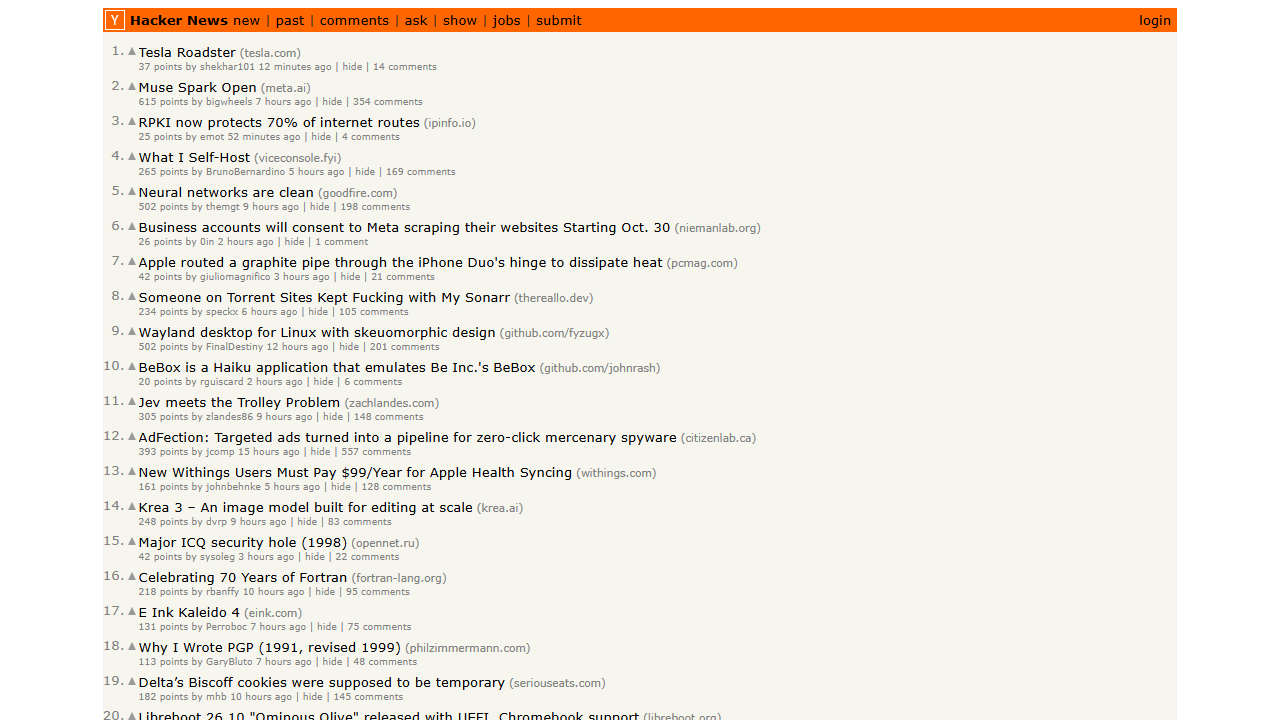

In [5]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## Step 4. 두 번째 MCP 서버 — Playwright

이번에는 `npx`(Node.js) 로 띄웁니다. **`MCPServerStdio` 사용법은 fetch 와 똑같습니다** —
`command` 와 `args` 만 다릅니다.

도구 목록을 보면 `browser_navigate` · `browser_click` · `browser_snapshot` 처럼
**사람이 브라우저에서 하는 동작**이 그대로 도구가 되어 있습니다.

> playwright 는 무겁고 느립니다(브라우저를 띄웁니다).
> **fetch 로 되는 페이지는 fetch 로** 하고, 안 될 때만 playwright 를 쓰세요.

In [6]:
playwright_params = {"command": "npx", "args": [ "@playwright/mcp@latest"]}

async with MCPServerStdio(params=playwright_params, client_session_timeout_seconds=60) as server:
    playwright_tools = await server.list_tools()

playwright_tools

[Tool(name='browser_close', title=None, description='Close the page', input_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {}, 'additionalProperties': False}, execution=None, output_schema=None, icons=None, annotations=ToolAnnotations(title='Close browser', read_only_hint=False, destructive_hint=True, idempotent_hint=None, open_world_hint=True), meta=None),
 Tool(name='browser_resize', title=None, description='Resize the browser window', input_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'width': {'type': 'number', 'description': 'Width of the browser window'}, 'height': {'type': 'number', 'description': 'Height of the browser window'}}, 'required': ['width', 'height'], 'additionalProperties': False}, execution=None, output_schema=None, icons=None, annotations=ToolAnnotations(title='Resize browser window', read_only_hint=False, destructive_hint=True, idempotent_hint=None, open_wor

## Step 5. 세 번째 MCP 서버 — filesystem (샌드박스)

```python
["-y", "@modelcontextprotocol/server-filesystem", sandbox_path]
```

마지막 인자로 넘긴 폴더가 이 서버가 다룰 수 있는 **전부**입니다.
그 바깥 경로를 요청하면 **서버가 거부**합니다.

### 여기가 중요합니다

샌드박스를 위해 따로 만든 장치가 없습니다. **서버를 띄울 때 넘긴 인자 하나가 곧 경계**입니다.

거부하는 주체가 **모델도 에이전트도 아니라 MCP 서버**라는 점을 기억하세요.
지시문에 "sandbox 밖에 쓰지 마"라고 적는 것과는 수준이 다릅니다 —
모델이 설득당해도(프롬프트 인젝션) 서버가 막습니다.

In [7]:
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))  # the only folder the filesystem server may touch
os.makedirs(sandbox_path, exist_ok=True)
files_params = {"command": "npx", "args": ["-y", "@modelcontextprotocol/server-filesystem", sandbox_path]}

async with MCPServerStdio(params=files_params, client_session_timeout_seconds=60) as server:
    file_tools = await server.list_tools()

file_tools

[Tool(name='read_file', title='Read File (Deprecated)', description='Read the complete contents of a file as text. DEPRECATED: Use read_text_file instead.', input_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'path': {'type': 'string'}, 'tail': {'description': 'If provided, returns only the last N lines of the file', 'type': 'number'}, 'head': {'description': 'If provided, returns only the first N lines of the file', 'type': 'number'}}, 'required': ['path']}, execution=ToolExecution(task_support='forbidden'), output_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'content': {'type': 'string'}}, 'required': ['content'], 'additionalProperties': False}, icons=None, annotations=ToolAnnotations(title=None, read_only_hint=True, destructive_hint=None, idempotent_hint=None, open_world_hint=False), meta=None),
 Tool(name='read_text_file', title='Read Text File', description="Read the comple

## Step 6. 에이전트에 MCP 서버 두 개 붙이기

```python
Agent(..., mcp_servers=[mcp_server_files, mcp_server_browser])
```

`mcp_servers` 에 넣기만 하면 **두 서버의 도구가 모두** 에이전트의 도구가 됩니다.
에이전트는 어느 서버의 도구인지 신경 쓰지 않고 필요한 것을 고릅니다.

이 예제에서 에이전트는 스스로 이렇게 움직입니다.

```
브라우저로 검색 → 조리법 페이지 열기 → 내용 읽기 → sandbox/ricecake.md 로 저장
```

**순서를 우리가 정하지 않았습니다.** 지시문과 도구만 주었습니다.

> `with trace("investigate")` 로 묶으면 LLM 호출과 **MCP 도구 호출까지** 하나의 기록이 됩니다.
> <https://platform.openai.com/traces> 에서 볼 수 있습니다.

> 실행에 몇 분 걸릴 수 있습니다. 브라우저를 띄우고 여러 페이지를 돌아다닙니다.

In [8]:
INSTRUCTIONS = """
You browse the internet to accomplish your instructions.
Accept cookies and navigate pop-ups as needed.
If one website isn't fruitful, try another.
Be persistent until you have solved your assignment,
trying different options and sites as needed.
When you need to write files, you do that inside the sandbox/ folder only.
"""

TASK = "바람떡에 대한 조리법을 검색하여, ricecake.md에 요약해 주세요"


async with MCPServerStdio(params=files_params, client_session_timeout_seconds=60) as mcp_server_files:
    async with MCPServerStdio(params=playwright_params, client_session_timeout_seconds=60) as mcp_server_browser:
        agent = Agent(
            name="investigator",
            instructions=INSTRUCTIONS,
            model="gpt-5.4-mini",
            mcp_servers=[mcp_server_files, mcp_server_browser]
            )
        with trace("investigate"):
            result = await Runner.run(agent, TASK, max_turns=20)
            print(result.final_output)

`ricecake.md`에 바람떡 조리법을 요약해 두었습니다.


## Step 7. 원격 MCP 서버에 접속하기

지금까지는 SDK가 **서버를 직접 띄웠습니다**(stdio). 이번에는 다릅니다.
이미 **다른 곳에서 돌고 있는 서버**에 HTTP로 접속합니다.

| | `MCPServerStdio` | `MCPServerStreamableHttp` |
|---|---|---|
| 서버를 누가 띄우나 | SDK가 자식 프로세스로 | **이미 떠 있음** |
| 설정에 필요한 것 | 실행 명령(`command`, `args`) | **URL** |
| 네트워크 | 쓰지 않음 | 씀 |

### 효과를 보여주는 실험

같은 질문을 **MCP 없이** 한 번, **원격 MCP 서버를 붙여서** 한 번 던집니다.
차이가 곧 MCP가 하는 일입니다.

In [9]:
from agents.mcp import MCPServerStreamableHttp

### 질문 — 모델이 모를 만한 것

최신 기능 비교처럼 **학습 시점 이후의 정보**를 묻습니다.
"모르면 모른다고 답하라"를 넣어, 모델이 지어내지 않고 한계를 드러내게 합니다.

In [10]:
question = """
Gemini MCP Sandbox 기능과 OpenAI MCP Sandbox 기능을 비교하면 비슷한 기능이 있나요? 정답을 모르면
대답하지 마시고 모른다고 응답하세요
"""

### (1) MCP 없이 — 모델의 기억만으로

In [11]:
agent = Agent(name="Expert", 
              instructions="Answer the question.", 
              model="gpt-4o-mini")
result = await Runner.run(agent, question)
print(result.final_output)

죄송하지만, Gemini MCP Sandbox와 OpenAI MCP Sandbox의 기능에 대한 구체적인 비교 정보를 제공할 수 없습니다. 더 자세한 내용을 알고 싶으시면 각 플랫폼의 공식 문서를 참조하시기 바랍니다.


### (2) 원격 MCP 서버를 붙여서

**Context7** 은 라이브러리·제품 문서를 찾아 주는 공개 MCP 서버입니다.
URL만 주면 끝이고, 설치할 것도 띄울 것도 없습니다.

```python
{"url": "https://mcp.context7.com/mcp", "timeout": 60}
```

앞 셀과 **질문도 모델도 같습니다.** 달라진 것은 MCP 서버 하나뿐입니다.

> 공개 서버는 언제든 주소가 바뀌거나 중단될 수 있습니다.
> 실무에서는 사내에 직접 띄우거나, 실패했을 때의 동작을 정해 두어야 합니다.

In [12]:
params = {"url": "https://mcp.context7.com/mcp", "timeout": 60}

async with MCPServerStreamableHttp(name="Context7", params=params) as server:
    agent = Agent(name="Expert", instructions="Use Context7 to answer the question.", mcp_servers=[server], model="gpt-4o-mini")
    result = await Runner.run(agent, question)

print(result.final_output)

비교를 위해 Gemini MCP Sandbox와 OpenAI MCP Sandbox의 기능을 살펴보겠습니다.

### Gemini MCP Sandbox
- **주요 기능**: 보안된 REST API, WebSocket 피드, FIX 연결을 통해 암호화폐 시장에 접근할 수 있도록 지원합니다.
- **목적**: 거래 애플리케이션, 시장 데이터 도구, 포트폴리오 추적 도구를 구축할 수 있는 개발자 플랫폼입니다.

### OpenAI MCP Sandbox
- **주요 기능**: ChatGPT와 Codex를 확장하고 사용자 정의 가능한 플러그인을 만들어 설치할 수 있는 능력을 제공합니다.
- **목적**: OpenAI의 모델을 활용하여 AI 애플리케이션을 구축하기 위한 API, 문서, 도구를 제공합니다.

### 비교
- **유사한 점**: 두 플랫폼 모두 개발자들이 특정 목적에 맞춰 커스터마이징할 수 있는 방법을 제공합니다. 
- **차이점**: Gemini는 주로 암호화폐 거래와 관련된 기능에 중점을 두고 있는 반면, OpenAI는 AI 모델과 관련된 기능을 제공하여 다양한 애플리케이션을 구축할 수 있도록 하며, 코딩 및 데이터 처리에 대한 지원이 중점적입니다.

결론적으로, 두 플랫폼은 비슷한 기능의 커스터마이징을 지원하지만, 적용 분야와 주된 기능에는 차이가 있습니다.


### 1부 정리

| | fetch | playwright | filesystem | Context7 |
|---|---|---|---|---|
| 클래스 | `MCPServerStdio` | `MCPServerStdio` | `MCPServerStdio` | `MCPServerStreamableHttp` |
| 띄우는 명령 | `uvx` | `npx` | `npx` | **없음 (URL)** |
| 리소스 | 인터넷 | 인터넷(브라우저) | **내 디스크** | 그 서버의 문서 |

**서버가 도는 곳과 리소스가 있는 곳은 별개입니다.**
fetch 서버는 내 PC에서 돌지만 인터넷을 봅니다. "로컬 서버라 안전하다"가 성립하지 않는 이유입니다.

---

# 2부 — Docker로 띄우기

## Docker로 MCP stdio 서버 실행하기

위에서는 `uvx`(Python), `npx`(Node)로 MCP 서버를 실행했습니다. 같은 서버를 **Docker 컨테이너**로도 실행할 수 있습니다.

| 실행 방법 | 필요한 것 | 특징 |
|---|---|---|
| `uvx` | Python + uv | 설치가 가볍고 빠름 |
| `npx` | Node.js | 설치가 가볍고 빠름 |
| `docker run` | Docker Desktop | 런타임 설치 없이 이미지 하나로 실행, **파일/네트워크 접근을 컨테이너 안으로 격리** |

stdio 방식은 "표준입출력으로 통신하는 프로세스를 띄운다"는 점이 같으므로, `command` 와 `args` 만 바꾸면 됩니다.

```python
{"command": "docker", "args": ["run", "-i", "--rm", "mcp/fetch"]}
```

| 옵션 | 의미 |
|---|---|
| `-i` | 표준입력(stdin)을 열어 둠 → **MCP stdio 통신에 반드시 필요** (`-t` 는 붙이면 안 됨) |
| `--rm` | 연결이 끝나 컨테이너가 종료되면 자동 삭제 |
| `mcp/fetch` | Docker Hub의 공식 MCP 이미지 이름 |

> **준비:** [Docker Desktop](https://www.docker.com/products/docker-desktop/) 설치 후 실행해 둡니다. 컨테이너 안을 확인하는 명령은 이 노트북 맨 끝 **부록**에 정리해 두었습니다.

### 1단계. Docker 실행 확인

Docker Desktop이 설치되어 있고 **실행 중**이어야 합니다. 꺼져 있으면 MCP 서버 연결이 실패합니다.

In [16]:
import shutil
import subprocess

if shutil.which("docker") is None:
    print("docker 명령을 찾을 수 없습니다. Docker Desktop을 설치하고 Jupyter 커널을 재시작하세요.")
else:
    result = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"], capture_output=True, text=True)
    if result.returncode == 0:
        print(f"Docker 엔진 실행 중 (버전 {result.stdout.strip()})")
    else:
        print("Docker Desktop이 실행되지 않았습니다. Docker Desktop을 먼저 실행하세요.")

Docker 엔진 실행 중 (버전 29.2.1)


### 2단계. 이미지 미리 받기

처음 `docker run` 을 하면 이미지를 내려받느라 시간이 오래 걸립니다.
그 사이 `client_session_timeout_seconds` 를 넘기면 `CancelledError` 가 발생하므로, **미리 `docker pull` 로 받아 둡니다.** (한 번만 하면 됩니다)

In [17]:
!docker pull mcp/fetch
!docker pull mcp/filesystem

Using default tag: latest
latest: Pulling from mcp/fetch
567b17f11bac: Pulling fs layer
a17051d9de56: Pulling fs layer
a056f49ed4fb: Pulling fs layer
524401bfa9eb: Pulling fs layer
68629629b516: Pulling fs layer
03952ff66d70: Pulling fs layer
76444abbd18a: Pulling fs layer
da47a1004a00: Download complete
76444abbd18a: Download complete
a056f49ed4fb: Download complete
2b71fc17c76b: Download complete
03952ff66d70: Download complete
524401bfa9eb: Download complete
567b17f11bac: Download complete
a17051d9de56: Download complete
68629629b516: Download complete
68629629b516: Pull complete
03952ff66d70: Pull complete
76444abbd18a: Pull complete
a056f49ed4fb: Pull complete
524401bfa9eb: Pull complete
a17051d9de56: Pull complete
567b17f11bac: Pull complete
Digest: sha256:1a7a0996a565a0b8ca5c41b42830d4e5f334d33f851596bbd9debb2beedb22d3
Status: Downloaded newer image for mcp/fetch:latest
docker.io/mcp/fetch:latest
Using default tag: latest
latest: Pulling from mcp/filesystem
74ff40609959: Pulling

### 3단계. fetch 서버를 Docker로 실행하기

맨 위에서 `uvx` 로 실행했던 `fetch_params` 와 비교해 보세요. **바뀐 것은 `command` 와 `args` 뿐**이고, `MCPServerStdio` 사용법은 똑같습니다.

```python
fetch_params        = {"command": "uvx",    "args": ["--with", "mcp<2", "mcp-server-fetch"]}
docker_fetch_params = {"command": "docker", "args": ["run", "-i", "--rm", "mcp/fetch"]}
```

`MCPServerStdio` 가 `docker run ...` 프로세스를 띄우고, 그 표준입출력으로 JSON-RPC 메시지를 주고받습니다.
`async with` 블록이 끝나면 stdin이 닫히면서 컨테이너가 종료되고, `--rm` 때문에 자동으로 삭제됩니다.

In [18]:
docker_fetch_params = {"command": "docker", "args": ["run", "-i", "--rm", "mcp/fetch"]}

async with MCPServerStdio(params=docker_fetch_params, client_session_timeout_seconds=60) as server:
    docker_fetch_tools = await server.list_tools()

# uvx로 실행했을 때와 같은 'fetch' 도구가 나옵니다.
[tool.name for tool in docker_fetch_tools]

['fetch']

### 4단계. filesystem 서버를 Docker로 실행하기 (폴더 마운트)

컨테이너는 내 PC와 격리되어 있어서, 그대로는 **내 PC의 파일을 볼 수 없습니다.**
`--mount` 옵션으로 허락한 폴더만 컨테이너 안에 연결해 줍니다.

```
내 PC:       D:\ai-edu\mcp\sandbox
                    │  (--mount 로 연결)
컨테이너:     /projects/sandbox
```

`npx` 로 실행한 filesystem 서버는 인자로 준 폴더만 쓰도록 **서버가 스스로 제한**합니다.
Docker로 실행하면 마운트하지 않은 폴더는 **컨테이너 안에 아예 존재하지 않으므로** 한 단계 더 안전합니다.

> Windows 경로(`D:\...`)는 Docker Desktop이 알아서 변환해 줍니다. 경로에 공백이 있어도 `--mount` 형식은 동작합니다.

In [19]:
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))
os.makedirs(sandbox_path, exist_ok=True)

docker_files_params = {
    "command": "docker",
    "args": [
        "run", "-i", "--rm",
        # 내 PC의 sandbox 폴더 → 컨테이너의 /projects/sandbox 로 연결
        "--mount", f"type=bind,src={sandbox_path},dst=/projects/sandbox",
        "mcp/filesystem",
        "/projects",  # 서버가 접근을 허용할 컨테이너 안의 경로
    ],
}

async with MCPServerStdio(params=docker_files_params, client_session_timeout_seconds=60) as server:
    docker_file_tools = await server.list_tools()

[tool.name for tool in docker_file_tools]

['read_file',
 'read_multiple_files',
 'write_file',
 'edit_file',
 'create_directory',
 'list_directory',
 'directory_tree',
 'move_file',
 'search_files',
 'get_file_info',
 'list_allowed_directories']

### 5단계. 에이전트에 Docker MCP 서버 두 개 연결하기

위의 Playwright 예제와 같은 방식으로, Docker로 띄운 `fetch` 서버와 `filesystem` 서버를 함께 에이전트에 연결합니다.
에이전트는 웹 페이지를 가져와 요약한 뒤 파일로 저장합니다.

에이전트 입장에서는 서버가 `uvx`로 떴는지 `docker`로 떴는지 **전혀 차이가 없습니다.** 도구 목록만 보고 사용합니다.

> 파일 경로는 **컨테이너 안의 경로**(`/projects/sandbox/...`)로 알려주어야 합니다.

In [20]:
DOCKER_INSTRUCTIONS = """
You can fetch web pages and write files.
Write files only inside the /projects/sandbox folder.
"""

DOCKER_TASK = """
Fetch https://modelcontextprotocol.io/introduction and summarize what MCP is in 5 bullet points (in Korean).
Save the summary as markdown to /projects/sandbox/mcp_summary.md
"""

async with MCPServerStdio(params=docker_fetch_params, client_session_timeout_seconds=60) as fetch_server:
    async with MCPServerStdio(params=docker_files_params, client_session_timeout_seconds=60) as files_server:
        agent = Agent(
            name="docker_mcp_agent",
            instructions=DOCKER_INSTRUCTIONS,
            model="gpt-4o-mini",
            mcp_servers=[fetch_server, files_server],
        )
        with trace("docker_mcp"):
            result = await Runner.run(agent, DOCKER_TASK, max_turns=10)
            print(result.final_output)

# 컨테이너 안의 /projects/sandbox 에 쓴 파일이 내 PC의 sandbox 폴더에 생겼는지 확인
print(open(os.path.join(sandbox_path, "mcp_summary.md"), encoding="utf-8").read())

The summary of the Model Context Protocol (MCP) has been created in Korean and saved as markdown. Here are the key points:

# MCP (모델 컨텍스트 프로토콜) 요약

1. MCP는 AI 응용 프로그램을 외부 시스템에 연결하기 위한 오픈 소스 표준입니다.
2. AI 응용 프로그램은 MCP를 통해 데이터 소스, 도구 및 워크플로우에 접근할 수 있습니다.
3. MCP는 개발 시간을 단축하고 AI 응용 프로그램의 기능을 향상시킵니다.
4. 다양한 클라이언트와 서버가 MCP를 지원하여 통합이 용이합니다.
5. 사용자는 더 향상된 AI 프로그램을 통해 개인 데이터를 기반으로 행동을 취할 수 있습니다.

You can find the summary in the file [mcp_summary.md](sandbox:/projects/sandbox/mcp_summary.md).
# MCP (모델 컨텍스트 프로토콜) 요약

1. MCP는 AI 응용 프로그램을 외부 시스템에 연결하기 위한 오픈 소스 표준입니다.
2. AI 응용 프로그램은 MCP를 통해 데이터 소스, 도구 및 워크플로우에 접근할 수 있습니다.
3. MCP는 개발 시간을 단축하고 AI 응용 프로그램의 기능을 향상시킵니다.
4. 다양한 클라이언트와 서버가 MCP를 지원하여 통합이 용이합니다.
5. 사용자는 더 향상된 AI 프로그램을 통해 개인 데이터를 기반으로 행동을 취할 수 있습니다.


### 정리

| 비교 | uvx / npx | docker run |
|---|---|---|
| params | `{"command": "uvx", "args": ["mcp-server-fetch"]}` | `{"command": "docker", "args": ["run", "-i", "--rm", "mcp/fetch"]}` |
| 파일 접근 | 내 PC 전체에 접근 가능 (서버가 스스로 제한) | **마운트한 폴더만** 접근 가능 |
| 첫 실행 | 패키지 다운로드 | 이미지 다운로드 (`docker pull` 로 미리 받기) |

**자주 만나는 문제**

- `CancelledError` / 타임아웃: Docker Desktop이 꺼져 있거나, 이미지를 받는 중입니다. 위 `docker pull` 셀을 먼저 실행하세요.
  (이 노트북 앞부분에서 서버의 에러 출력을 `DEVNULL` 로 숨겼기 때문에 원인이 보이지 않습니다. 터미널에서 `docker run -i --rm mcp/fetch` 를 직접 실행해 보면 원인을 확인할 수 있습니다.)
- `-i` 를 빼면 서버가 입력을 받지 못해 바로 종료됩니다.
- 에이전트가 만든 파일은 컨테이너 안이 아니라 **마운트한 `sandbox/` 폴더**에 남습니다. `--rm` 으로 컨테이너가 삭제되어도 파일은 유지됩니다.

## 부록. 컨테이너 안을 들여다보는 명령

에이전트가 만든 파일이 정말 내 PC의 `sandbox/` 에 있는지, 컨테이너에서 확인하는 방법입니다.
`alpine` 은 아주 작은 리눅스 이미지로, 잠깐 띄워 안을 들여다볼 때 씁니다.

**파일 목록 보기**

```bash
docker run --rm --mount type=bind,src=D:\ai-edu\mcp\sandbox,dst=/projects/sandbox alpine ls -la /projects/sandbox
```

**파일 내용 보기**

```bash
docker run --rm --mount type=bind,src=D:\ai-edu\mcp\sandbox,dst=/projects/sandbox alpine cat /projects/sandbox/mcp_summary.md
```

**컨테이너 안으로 들어가서 둘러보기**

```bash
docker run --rm -it --mount type=bind,src=D:\ai-edu\mcp\sandbox,dst=/projects/sandbox alpine sh
```

> `src=` 경로는 **여러분 PC의 실제 sandbox 경로**로 바꿔 주세요.
> 노트북에서 `print(sandbox_path)` 로 확인할 수 있습니다.